# Consumer Complaint Classification
### From financial narratives to complaint routing
**Instant AI & Data Analysis Training · Sprint 03 · Project 01**

We compare three custom recurrent classifiers—SimpleRNN, LSTM and GRU—with a fine-tuned DistilBERT.
The task is to assign an English complaint to one of five financial-product categories.

**Completed experiment:** 123,978 retained complaints; four trained models; a deployment model
selected using validation macro F1 before the final test phase. DistilBERT achieved **85.43% test
accuracy** and **0.8467 test macro F1**.

**How to use this notebook:** read the saved outputs, or Run All to rebuild its analysis on CPU.
The default walkthrough is self-contained: small evidence files, the trained vocabulary and
tokenizer are embedded. No dataset download, model-weight download, GPU or retraining is triggered.
Historical training results are explicitly loaded from the completed run. Section 12 offers
optional live inference from an existing local bundle. The separate executed Kaggle notebook
preserves the full download → preparation → training → evaluation → export workflow.

**Contents:** 1. Evidence · 2. Dataset · 3. EDA · 4. Preprocessing · 5. Sequences and padding ·
6. Embeddings · 7. Architectures · 8. Training · 9. Validation selection · 10. Final evaluation ·
11. Error analysis · 12. Inference and application · 13. Conclusions and reproducibility.

## 1. Load the frozen experiment evidence
The compact cell below unpacks report data, not trained neural weights. Keeping the evidence
inside the notebook makes tables and figures reproducible after moving this file.
The original report files remain in the project’s `reports/` directory.

Dependencies for Run All: Python 3.11+, NumPy, pandas, Matplotlib, tokenizers and PyTorch.
No installation command runs automatically. Kaggle already supplies most of these libraries.

In [1]:
import base64, hashlib, json, zlib
PAYLOAD = '...'
E = json.loads(zlib.decompress(base64.b64decode(PAYLOAD)))
assert hashlib.sha256(json.dumps(E, sort_keys=True, ensure_ascii=False).encode()).hexdigest() == '1fdf1bb167e5a1083bce13f9c55265574d5a58ef9f85b73eb50c89bdc2a4b92d'
print('Embedded evidence verified. Experiment:', E['selection']['signature'][:16])

Embedded evidence verified. Experiment: bd457ca03f08e8a7


In [2]:
from pathlib import Path
import io, math, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code

NAMES = {'rnn': 'SimpleRNN', 'lstm': 'LSTM', 'gru': 'GRU', 'distilbert': 'DistilBERT'}
LABELS = E['audit']['labels']
PRETTY = {label: label.replace('_', ' ').capitalize() for label in LABELS}
COLORS = ['#94a3b8', '#14b8a6', '#3b82f6', '#7c3aed']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 12, 'font.size': 10})
audit, config = E['audit'], E['config']
def show():
    plt.tight_layout()
    plt.show()
    plt.close('all')
display(pd.DataFrame([{'Stage': 'Source CSV', 'Records': audit['source_rows']},
                      {'Stage': 'Retained', 'Records': audit['retained_rows']},
                      *[{'Stage': k, 'Records': v} for k, v in audit['split_counts'].items()]]))

,Stage,Records
0,Source CSV,162421
1,Retained,123978
2,train,99182
3,validation,12398
4,test,12398


## 2. Understand the dataset and target
Source: [Consumer Complaints Dataset for NLP, version 1](https://www.kaggle.com/datasets/shashwatwork/consume-complaints-dataset-fo-nlp).
Its 162,421 rows contain `Unnamed: 0`, `product`, and `narrative`. We predict `product` from
`narrative`; the index column is not a model feature. There are no official train/validation/test splits.

**Upstream processing matters:** all supplied narratives already contain lowercase alphabetic words
and whitespace. Original punctuation, numbers, casing, and original complaint identifiers are
unavailable. We cannot claim to recover raw complaints or undo the publisher’s cleaning.

The following are **real training examples** from the exact completed experiment. Their source IDs
identify rows in this dataset, not original CFPB complaint identifiers. Ten examples and the vocabulary
were recovered from an already-downloaded archive; record, vocabulary and encoded-array hashes match
the completed experiment byte for byte.

In [3]:
examples = pd.DataFrame(E['examples'])
display(examples[['source_id', 'product', 'split']].head(10))
display(examples[['product', 'narrative']].assign(narrative=lambda x: x.narrative.str.slice(0, 260)))
print('Source CSV SHA-256:', audit['source_csv_sha256'])
print('Recovered teaching assets:', E['recovery']['status'])

Source CSV SHA-256: a120ac8450cb3839bf0085bbae68f7c0f3b5351302cafd0bc85ae27a251010b4
Recovered teaching assets: passed


,source_id,product,split
0,0,credit_card,train
1,1,credit_card,train
2,2,retail_banking,train
3,4,credit_reporting,train
4,5,credit_reporting,train
5,14,debt_collection,train
6,15,mortgages_and_loans,train
7,16,mortgages_and_loans,train
8,25,debt_collection,train
9,34,retail_banking,train


,product,narrative
0,credit_card,purchase order day shipping amount receive pro...
1,credit_card,forwarded message date tue subject please inve...
2,retail_banking,forwarded message cc sent friday pdt subject f...
3,credit_reporting,payment history missing credit report made mis...
4,credit_reporting,payment history missing credit report made mis...
5,debt_collection,collection agency system inc mn phone sent let...
6,mortgages_and_loans,current loan provident funding applied refinan...
7,mortgages_and_loans,current loan got deferment paid back credit hi...
8,debt_collection,purchased laptop laptop damaged turned repair ...
9,retail_banking,negative transfer loading transaction detail p...


## 3. Explore quality, class balance, and sequence lengths
Cleaning removes blank rows, contradictory duplicate labels and repeated narratives. Additional
grouping keeps complaints that become identical after tokenization/truncation in the same split.
This is stronger than simply splitting rows randomly, although semantic paraphrases may remain.

,stage,remaining,excluded
0,source,162421,0
1,blank_text_or_label,162411,10
2,conflicting_source_text_labels,159134,3277
3,duplicate_source_text,124300,34834
4,empty_after_recurrent_cleaning,124300,0
5,conflicting_recurrent_text_labels,124278,22
6,duplicate_recurrent_text,123978,300


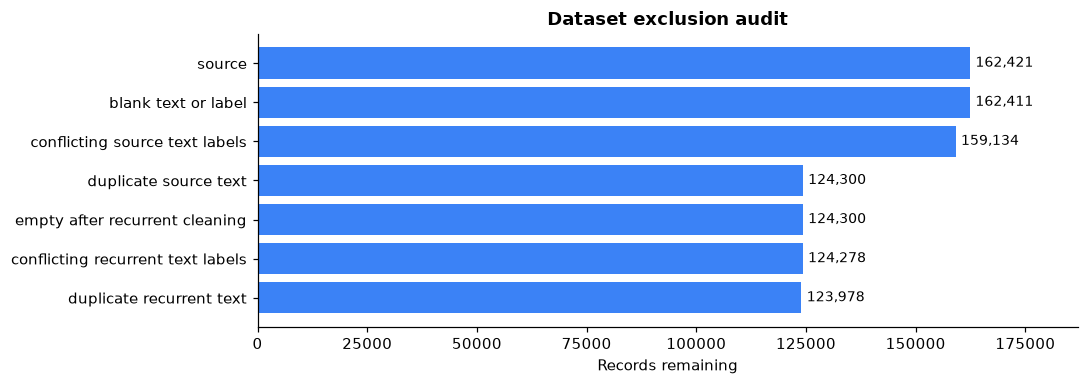

In [4]:
flow = pd.DataFrame(audit['exclusion_flow'])
display(flow)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.barh(flow.stage.str.replace('_', ' '), flow.remaining, color='#3b82f6')
ax.invert_yaxis(); ax.set_xlabel('Records remaining'); ax.set_title('Dataset exclusion audit')
for i, row in flow.iterrows():
    ax.text(row.remaining + 1200, i, f'{row.remaining:,}', va='center', fontsize=9)
ax.set_xlim(0, 187000)
show()

Largest class: 45.1% of training data.
Split policy: 10 StratifiedGroupKFold folds with seed 42: fold 0 validation, fold 1 test, other folds train. Truncated-input equivalence groups stay together.


,train,validation,test,total
credit_card,11966,1496,1496,14958
credit_reporting,44712,5590,5589,55891
debt_collection,16777,2097,2097,20971
mortgages_and_loans,14959,1869,1870,18698
retail_banking,10768,1346,1346,13460


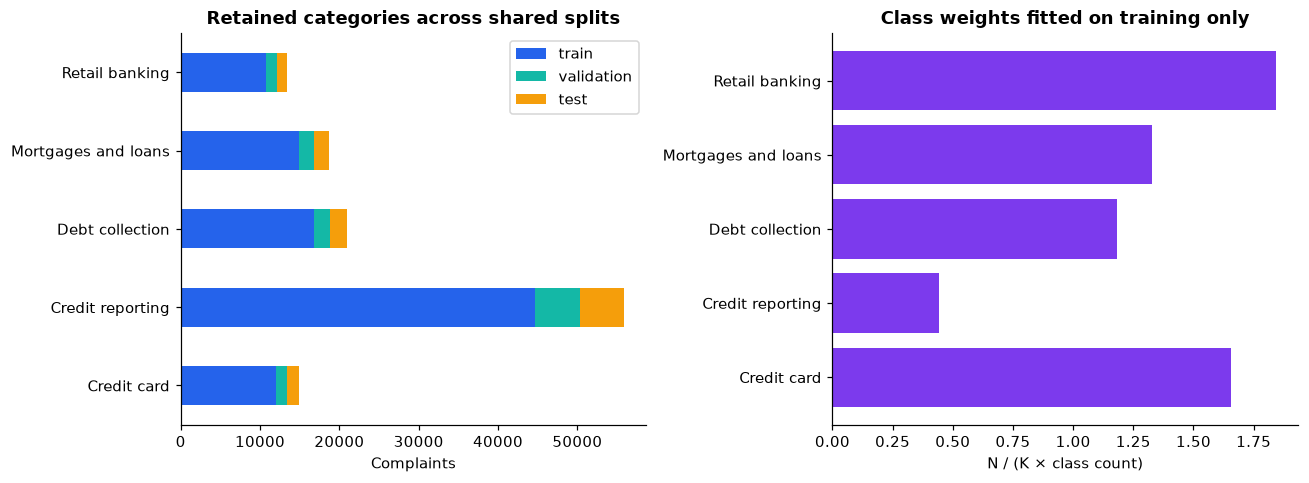

,Cross-split overlaps
normalized_source_text,0
recurrent_cleaned_text,0
recurrent_encoded_input,0
transformer_encoded_input,0


In [5]:
counts = pd.DataFrame(audit['class_counts_by_split']).reindex(LABELS)[['train','validation','test']]
display(counts.assign(total=counts.sum(axis=1)))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
counts.rename(index=PRETTY).plot.barh(stacked=True, ax=axes[0], color=['#2563eb','#14b8a6','#f59e0b'])
axes[0].set_title('Retained categories across shared splits'); axes[0].set_xlabel('Complaints')
weights = pd.Series(audit['training_class_weights']).reindex(LABELS)
axes[1].barh([PRETTY[k] for k in LABELS], weights, color='#7c3aed')
axes[1].set_title('Class weights fitted on training only'); axes[1].set_xlabel('N / (K × class count)')
show()
print(f"Largest class: {counts.train.max() / counts.train.sum():.1%} of training data.")
print('Split policy:', audit['split_policy'])
display(pd.DataFrame([audit['duplicate_overlap_between_splits']]).T.rename(columns={0:'Cross-split overlaps'}))

Credit reporting dominates the dataset, so accuracy alone could conceal weak smaller-category
performance. All four models use training-derived class-weighted cross-entropy. Validation and
test distributions retain their observed proportions. **Macro F1** gives every class equal weight.

The final split contains **99,182 training / 12,398 validation / 12,398 test** records.
The learned vocabulary and class weights use training data only. Fixed pretrained tokenization and
duplicate grouping are used to audit split isolation; test predictions never guide model selection.

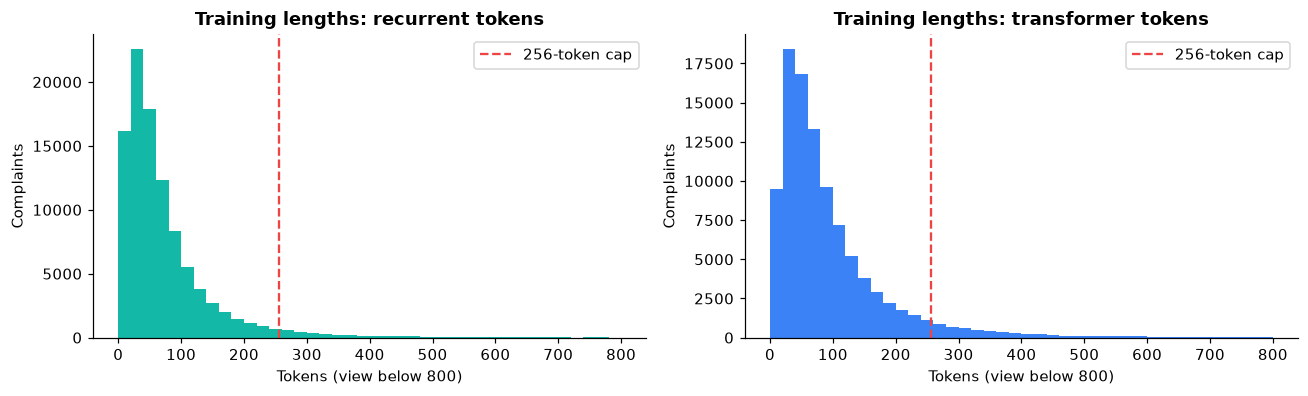

,Representation,Training median tokens,Training p95 tokens,Training truncated
0,recurrent,51.0,222.0,0.036609
1,transformer,66.0,282.0,0.060848


In [6]:
histogram = pd.DataFrame(E['length_histogram'])
for col in ['left','right','count']: histogram[col] = histogram[col].astype(int)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.7))
for ax, kind, color in zip(axes, ['recurrent','transformer'], ['#14b8a6','#3b82f6']):
    frame = histogram.loc[(histogram.representation == kind) & (histogram.left < 800)]
    ax.bar(frame.left, frame['count'], width=frame.right-frame.left, align='edge', color=color)
    ax.axvline(256, color='#ef4444', linestyle='--', label='256-token cap')
    ax.set_title(f'Training lengths: {kind} tokens'); ax.set_xlabel('Tokens (view below 800)')
    ax.set_ylabel('Complaints'); ax.legend()
show()
display(pd.DataFrame([{'Representation': k,
    'Training median tokens': audit['lengths']['train'][k+'_length_percentiles']['50'],
    'Training p95 tokens': audit['lengths']['train'][k+'_length_percentiles']['95'],
    'Training truncated': audit['lengths']['train'][k+'_truncation_fraction']}
    for k in ['recurrent','transformer']]))

A 256-token cap covers most complaints but truncates **3.66%** of recurrent training inputs and
**6.08%** of transformer training inputs. Word tokens and transformer subwords are different units.
Length and capacity choices are part of this fixed experiment; the test set is not used to retune them.

## 4. Follow the two preprocessing paths
Recurrent models use NFKC normalization, case folding, non-letter removal, and a fixed stop-word
list. Negations such as `not`, `never`, and `without` are preserved. Lemmatization/stemming is optional
in the assignment and was omitted.

DistilBERT uses the supplied narrative after normalization with its pretrained tokenizer. We do not
additionally remove stop words or punctuation from this branch. The source itself was already cleaned;
this comparison therefore concerns complete modeling pipelines, not architecture alone.

In [7]:
# Execute the exact small preprocessing module embedded from the experiment.
exec(E['source']['text.py'])
stopwords = set(E['preprocessing']['stopwords'])
sample = examples.iloc[0].narrative
display(pd.DataFrame({'Stage': ['Dataset narrative','Normalized','Recurrent-cleaned'],
                      'Text': [sample, normalize_text(sample), clean_recurrent(sample, stopwords)]}))
# This invented sentence illustrates operations absent from the already-cleaned source.
illustrative_raw = 'My BANK charged $25 twice!!! I did NOT authorize this payment.'
display(pd.DataFrame({'Illustrative input': [illustrative_raw],
                      'Recurrent output': [clean_recurrent(illustrative_raw, stopwords)]}))
assert 'not' in clean_recurrent(illustrative_raw, stopwords).split()

,Stage,Text
0,Dataset narrative,purchase order day shipping amount receive pro...
1,Normalized,purchase order day shipping amount receive pro...
2,Recurrent-cleaned,purchase order day shipping receive product we...


,Illustrative input,Recurrent output
0,My BANK charged $25 twice!!! I did NOT authori...,bank charged twice did not authorize payment


## 5. Convert words into IDs, truncate, and pad
The actual recurrent vocabulary contains **30,000 entries**, including `<PAD>=0` and `<UNK>=1`.
Words are ordered by training frequency with an alphabetical tie break. Unknown validation or future
words receive ID 1. Encoded arrays are stored with length 256, and the collator trims/pads each batch
to its longest actual sequence. Packed sequences prevent padding from changing the final hidden state.

In [8]:
vocabulary = E['vocabulary']  # exact training-only vocabulary, not a toy mapping
words = clean_recurrent(sample, stopwords).split()
ids = encode_recurrent(sample, vocabulary, stopwords, config['recurrent_max_length'])
padded = np.pad(np.asarray(ids), (0, 256-len(ids)))
display(pd.DataFrame({'Word': words[:18], 'Training vocabulary ID': ids[:18]}))
print('Actual word count:', len(words), '| Used:', len(ids), '| Stored shape:', padded.shape)
print('Padding starts:', padded[len(ids):len(ids)+12].tolist())
print('Unseen-word ID:', vocabulary.get('zzzxxyyunseenword', UNK_ID))
assert vocabulary['<PAD>'] == 0 and vocabulary['<UNK>'] == 1
assert len(vocabulary) == 30000 and np.all(padded[len(ids):] == 0)

Actual word count: 204 | Used: 204 | Stored shape: (256,)
Padding starts: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Unseen-word ID: 1


,Word,Training vocabulary ID
0,purchase,146
1,order,177
2,day,14
3,shipping,1644
4,receive,108
5,product,614
6,week,127
7,sent,18
8,followup,5063
9,email,43


In [9]:
from tokenizers import Tokenizer
tokenizer = Tokenizer.from_str(E['tokenizer'])  # actual exported tokenizer; offline
transformer_example = tokenizer.encode(normalize_text(sample))
display(pd.DataFrame({'Subword / special token': transformer_example.tokens[:24],
                      'Token ID': transformer_example.ids[:24]}))
tokenizer.enable_truncation(max_length=256)
tokenizer.enable_padding(length=256, pad_id=0, pad_token='[PAD]')
encoded = tokenizer.encode(normalize_text(sample))
print('Transformer input IDs:', len(encoded.ids), '| Mask length:', len(encoded.attention_mask))
print('Non-padding tokens:', sum(encoded.attention_mask))
assert len(encoded.ids) == len(encoded.attention_mask) == 256

Transformer input IDs: 256 | Mask length: 256
Non-padding tokens: 256


,Subword / special token,Token ID
0,[CLS],101
1,purchase,5309
2,order,2344
3,day,2154
4,shipping,7829
5,amount,3815
6,receive,4374
7,product,4031
8,week,2733
9,sent,2741


## 6. Understand the learned embedding
An embedding maps each word ID to a dense vector. Our custom models learn a **30,000 × 128**
table during supervised training. The next cell demonstrates the same layer and tensor shapes with
freshly initialized values; it does **not** load trained embedding weights or train a model.
Pretrained GloVe/FastText vectors are not required for this assignment.

In [10]:
import torch
from torch import nn
torch.manual_seed(42)
embedding_demo = nn.Embedding(len(vocabulary), 128, padding_idx=0)
demonstration_batch = torch.tensor([padded[:32]], dtype=torch.long)
with torch.inference_mode(): vectors = embedding_demo(demonstration_batch)
print('ID batch:', tuple(demonstration_batch.shape), '→ Embeddings:', tuple(vectors.shape))
print('Embedding parameters:', embedding_demo.weight.numel())
assert torch.count_nonzero(embedding_demo.weight[0]) == 0
del embedding_demo, vectors

ID batch: (1, 32) → Embeddings: (1, 32, 128)
Embedding parameters: 3840000


<ipython-input-10-f9789660122d>:5: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\torch\csrc\utils\tensor_new.cpp:281.)
  demonstration_batch = torch.tensor([padded[:32]], dtype=torch.long)


## 7. Build and explain all four architectures
The custom classifiers share the same learned embedding, hidden size, dropout and classification
head. Their recurrent cell differs. RNN updates one hidden state; LSTM adds a gated memory cell;
GRU uses update/reset gates with fewer parameters than LSTM. These gates can help preserve useful
information across longer sequences.

| Model | Data flow | Initialization |
|---|---|---|
| SimpleRNN | IDs → embedding → packed RNN → final hidden state → dropout → linear head | Learned from scratch |
| LSTM | IDs → embedding → packed LSTM → final hidden state → dropout → linear head | Learned from scratch |
| GRU | IDs → embedding → packed GRU → final hidden state → dropout → linear head | Learned from scratch |
| DistilBERT | Subword IDs + mask → pretrained encoder → sequence-classification head | All encoder and head parameters fine-tuned |

The next cell shows the **actual model definitions** used by the experiment. Showing them does not
download pretrained weights or start training.

In [11]:
display(Code(E['source']['models.py'], language='python'))

"""Comparable single-layer recurrent classifiers and genuine DistilBERT tuning."""
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence


class RecurrentClassifier(nn.Module):
    def __init__(self, kind, vocab_size, num_labels, embedding_dim=128, hidden_dim=128, dropout=0.3):
        super().__init__()
        if kind not in {"rnn", "lstm", "gru"}:
            raise ValueError(kind)
        self.architecture = dict(kind=kind, vocab_size=vocab_size, num_labels=num_labels,
                                 embedding_dim=embedding_dim, hidden_dim=hidden_dim, dropout=dropout)
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        cls = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[kind]
        self.recurrent = cls(embedding_dim, hidden_dim, num_layers=1, batch_first=True, bidirectional=False)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, num_labels)

    def forward(self, input_ids, lengths):
        embedded = self.embedding(input_ids)
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, hidden = self.recurrent(packed)
        if isinstance(hidden, tuple):
            hidden = hidden[0]
        return self.classifier(self.dropout(hidden[-1]))


def create_model(kind, data, config, pretrained=True):
    if kind != "distilbert":
        return RecurrentClassifier(kind=kind, vocab_size=len(data.vocabulary), num_labels=len(data.label_names),
                                   embedding_dim=config["embedding_dim"], hidden_dim=config["hidden_dim"], dropout=config["dropout"])
    from transformers import AutoConfig, AutoModelForSequenceClassification
    arguments = dict(num_labels=len(data.label_names), id2label={i: name for i, name in enumerate(data.label_names)},
                     label2id=data.labels["label2id"])
    if pretrained:
        model = AutoModelForSequenceClassification.from_pretrained(
            config["transformer_checkpoint"], revision=config["transformer_revision"],
            use_safetensors=True, attn_implementation="eager", **arguments)
    else:
        hf_config = AutoConfig.from_pretrained(data.root / "tokenizer", local_files_only=True, **arguments)
        model = AutoModelForSequenceClassification.from_config(hf_config, attn_implementation="eager")
    assert all(parameter.requires_grad for parameter in model.parameters()), "Encoder must be fine-tuned"
    return model


def forward_batch(model, kind, batch, device):
    ids = batch["input_ids"].to(device, non_blocking=True)
    if kind == "distilbert":
        mask = (ids != 0).long()
        return model(input_ids=ids, attention_mask=mask).logits
    return model(ids, batch["lengths"])

## 8. Training procedure and observed learning curves
All models use the same record-level splits, class weights, and seed 42. Recurrent models use Adam,
learning rate 0.001, batch size 128, and an eight-epoch ceiling. DistilBERT uses AdamW, learning rate
0.00002, batch size 16 with two-step accumulation, and three epochs. Hidden and embedding dimensions
are 128; classifier dropout is 0.3.

Training uses weighted cross-entropy, gradient clipping, CUDA mixed precision, and early stopping
with patience 2. Checkpoints are selected by validation macro F1. Two T4 GPUs execute independent
models; DistilBERT itself is not distributed across both GPUs.

The following function is the actual training implementation, including initialization, batching,
loss, backpropagation, evaluation and checkpoint saving. It is shown for study. **Historical metrics
below come from saved reports; this walkthrough does not pretend to retrain the models.**

In [12]:
import ast
training_source = E['source']['training.py']
tree = ast.parse(training_source)
function = next(node for node in tree.body if isinstance(node, ast.FunctionDef) and node.name == 'run_model')
display(Code('\n'.join(training_source.splitlines()[function.lineno-1:function.end_lineno]), language='python'))

def run_model(kind, data, config, output_root, device, verification=False, train_indices=None, validation_indices=None):
    if kind not in {"rnn", "lstm", "gru", "distilbert"}:
        raise ValueError(kind)
    device = torch.device(device)
    signature, signature_payload = experiment_signature(data, config)
    output = Path(output_root) / "models" / kind
    completed = output / "result.json"
    if completed.exists():
        result = read_json(completed)
        if result["signature"] != signature or result["verification"] != verification:
            raise RuntimeError(f"{kind}: existing outputs belong to a different experiment. Choose a new OUTPUT_DIR; existing results will not be overwritten.")
        if sha256(output / "best.pt") != result["checkpoint_sha256"]:
            raise RuntimeError(f"{kind}: checkpoint checksum failed")
        print(f"{kind}: reusing compatible completed run", flush=True)
        return result
    if output.exists() and any(output.iterdir()):
        previous = read_json(output / "run_identity.json") if (output / "run_identity.json").exists() else None
        if previous and previous["signature"] != signature:
            raise RuntimeError(f"{kind}: partial outputs have a different configuration. Choose a new OUTPUT_DIR.")
        print(f"{kind}: restarting an incomplete run from epoch 1 (weights-only checkpoints do not resume optimization).", flush=True)
        shutil.rmtree(output)
    output.mkdir(parents=True, exist_ok=True)
    write_json(output / "run_identity.json", {"signature": signature, "verification": verification, "identity": signature_payload})
    seed_everything(config["seed"])
    start = time.perf_counter()
    model = create_model(kind, data, config, pretrained=True).to(device)
    loader = make_loader(data, "train", kind, config, device, train_indices, shuffle=True)
    validation = make_loader(data, "validation", kind, config, device, validation_indices)
    weights = torch.tensor(data.preprocessing["class_weights"], dtype=torch.float32, device=device)
    if kind == "distilbert":
        no_decay = ("bias", "LayerNorm.weight", "layer_norm.weight")
        groups = [{"params": [p for n, p in model.named_parameters() if not any(x in n for x in no_decay)], "weight_decay": config["transformer_weight_decay"]},
                  {"params": [p for n, p in model.named_parameters() if any(x in n for x in no_decay)], "weight_decay": 0.0}]
        optimizer = torch.optim.AdamW(groups, lr=config["transformer_lr"])
        from transformers import get_linear_schedule_with_warmup
        epochs = config["transformer_epochs"]
        accumulation = config["gradient_accumulation_steps"]
        updates = math.ceil(len(loader) / accumulation) * epochs
        scheduler = get_linear_schedule_with_warmup(optimizer, int(updates * config["warmup_ratio"]), updates)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=config["recurrent_lr"])
        epochs = config["recurrent_epochs"]
        accumulation = 1
        scheduler = None
    use_amp = config["mixed_precision"] and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    best_f1, best_epoch, stale, monitor_best = -1.0, 0, 0, -1.0
    history = []
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)
    first_batches = []
    for epoch in range(1, epochs + 1):
        epoch_start = time.perf_counter()
        model.train()
        optimizer.zero_grad(set_to_none=True)
        total_loss, total_weight = 0.0, 0.0
        for step, batch in enumerate(tqdm(loader, desc=f"{kind} epoch {epoch}/{epochs}", leave=False, disable=not sys.stderr.isatty())):
            batch_start = time.perf_counter()
            targets = batch["labels"].to(device, non_blocking=True)
            group_start = (step // accumulation) * accumulation
            group_size = min(accumulation, len(loader) - group_start)
            with torch.autocast(device_type=device.type, dtype=to

,Model,Best epoch,Epochs run,Trainable parameters,Training minutes,Checkpoint MiB
0,SimpleRNN,3,5,3873669,1.393,14.780
1,LSTM,7,8,3972741,2.294,15.158
2,GRU,7,8,3939717,2.232,15.032
3,DistilBERT,3,3,66957317,41.444,255.454


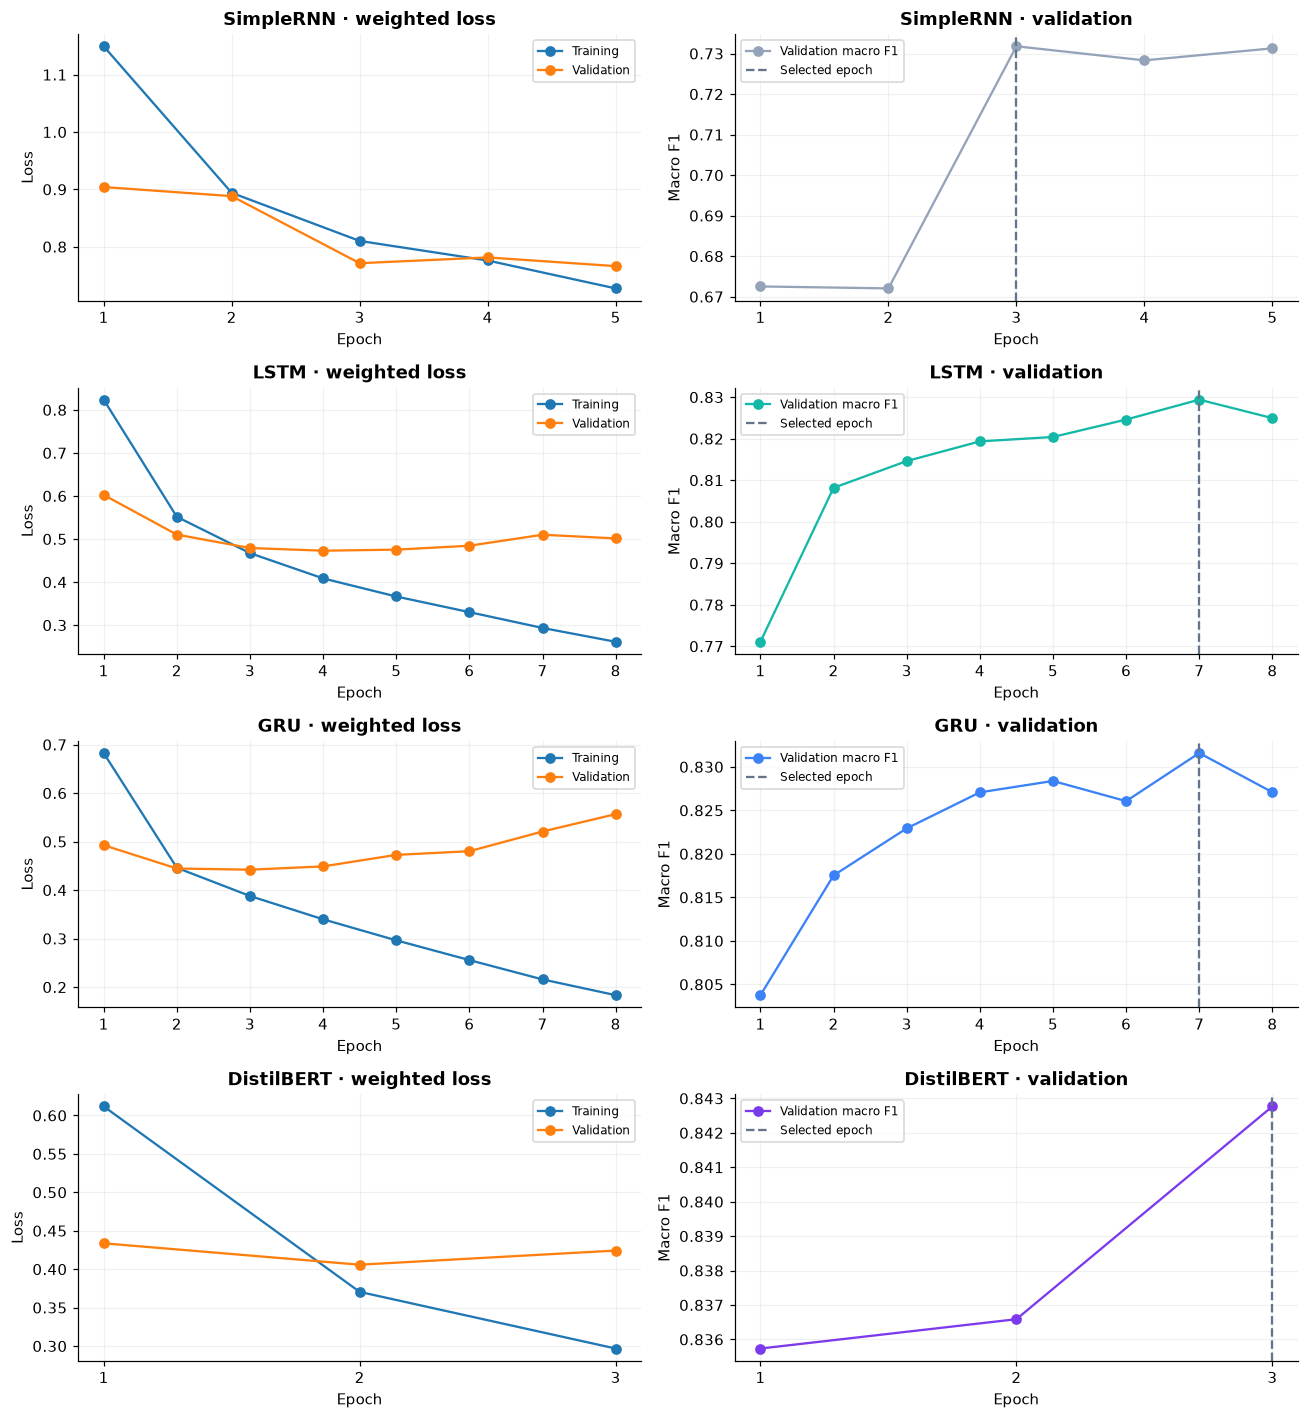

In [13]:
training = pd.DataFrame([{'Model': NAMES[k], 'Best epoch': v['result']['best_epoch'],
    'Epochs run': v['result']['epochs_run'], 'Trainable parameters': v['result']['trainable_parameters'],
    'Training minutes': v['result']['training_seconds_including_initialization']/60,
    'Checkpoint MiB': v['result']['checkpoint_bytes']/2**20} for k, v in E['models'].items()])
display(training.round(3))
fig, axes = plt.subplots(4, 2, figsize=(12, 13))
for row, (kind, record) in enumerate(E['models'].items()):
    h = pd.DataFrame(record['history'])
    axes[row,0].plot(h.epoch, h.training_loss, marker='o', label='Training')
    axes[row,0].plot(h.epoch, h.validation_loss, marker='o', label='Validation')
    axes[row,0].set_title(NAMES[kind] + ' · weighted loss'); axes[row,0].set_ylabel('Loss')
    axes[row,1].plot(h.epoch, h.validation_macro_f1, marker='o', color=COLORS[row], label='Validation macro F1')
    axes[row,1].axvline(record['result']['best_epoch'], color='#64748b', linestyle='--', label='Selected epoch')
    axes[row,1].set_title(NAMES[kind] + ' · validation'); axes[row,1].set_ylabel('Macro F1')
    for ax in axes[row]:
        ax.set_xlabel('Epoch'); ax.set_xticks(h.epoch); ax.grid(alpha=.18); ax.legend(fontsize=8)
show()

LSTM and GRU substantially improve on the SimpleRNN baseline in this run. DistilBERT obtains the
strongest validation macro F1. Its training loss falls while validation loss does not fall monotonically;
the selected checkpoint follows the declared F1 criterion, not the lowest validation loss.

Training durations are read consistently from `reports/models/*/result.json`. Some original notebook
timing outputs differ from the extracted reports; timings are descriptive observations, not benchmark
rankings. Concurrent workers and initialization affect them. The model scores and checkpoint identities
agree with the frozen selection.

## 9. Select using validation before looking at final test scores
The predeclared rule chooses the highest validation macro F1. Within **0.001 absolute F1**, its
tie priority is SimpleRNN → GRU → LSTM → DistilBERT. DistilBERT wins outside that tolerance.
The saved selection has status `frozen_before_test`; final test outcomes do not change the winner.

Selected: DistilBERT


,Model,Validation accuracy,Validation macro F1
0,SimpleRNN,0.7508,0.7318
1,LSTM,0.8422,0.8294
2,GRU,0.8448,0.8316
3,DistilBERT,0.8505,0.8428


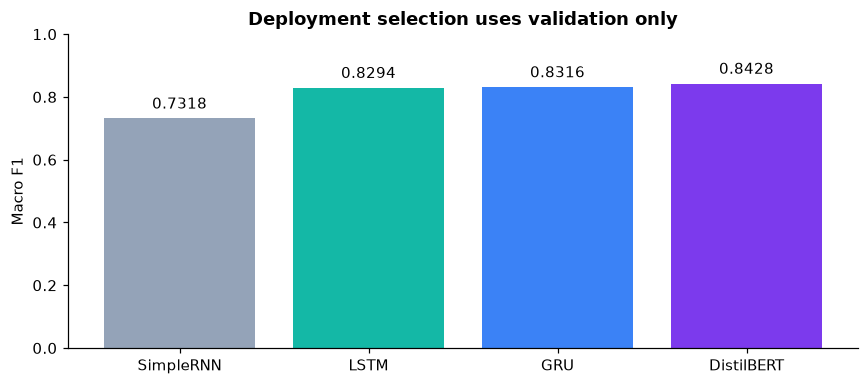

In [14]:
validation = pd.DataFrame([{'Model': NAMES[k],
    'Validation accuracy': v['result']['validation_accuracy'],
    'Validation macro F1': v['result']['validation_macro_f1']} for k,v in E['models'].items()])
display(validation.round(4))
fig, ax = plt.subplots(figsize=(8,3.6))
bars = ax.bar(validation.Model, validation['Validation macro F1'], color=COLORS)
ax.set_ylim(0,1); ax.set_ylabel('Macro F1'); ax.set_title('Deployment selection uses validation only')
ax.bar_label(bars, fmt='%.4f', padding=4)
show()
assert E['selection']['selected_model'] == 'distilbert'
assert E['selection']['test_outcomes_used_for_selection'] is False
print('Selected:', NAMES[E['selection']['selected_model']])

## 10. Evaluate the frozen models on the held-out test split
All four best checkpoints were evaluated in the final reporting phase on **12,398** test records.
The cells below rebuild visualizations from saved test metrics and confusion counts. They perform
no new test inference or tuning.

,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
Model,,,,,
SimpleRNN,0.7472,0.7134,0.7484,0.7263,0.7514
LSTM,0.8374,0.8126,0.8358,0.8231,0.8389
GRU,0.8414,0.8185,0.8362,0.8263,0.8429
DistilBERT,0.8543,0.8320,0.8652,0.8467,0.8557


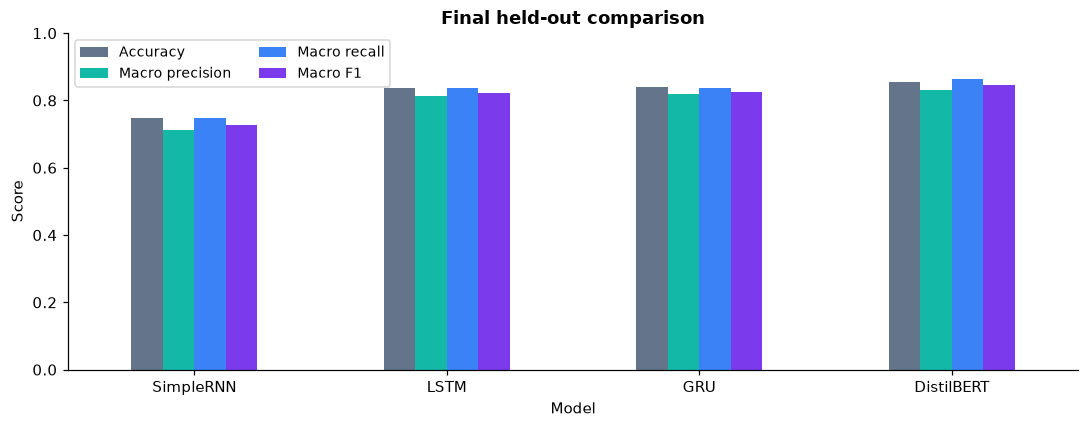

In [15]:
fields = ['accuracy','macro_precision','macro_recall','macro_f1','weighted_f1']
comparison = pd.DataFrame([{'Model': NAMES[k], **{f:v['test'][f] for f in fields}}
                            for k,v in E['models'].items()]).set_index('Model')
display(comparison.round(4))
fig, ax = plt.subplots(figsize=(10,4))
comparison[['accuracy','macro_precision','macro_recall','macro_f1']].plot.bar(ax=ax,
    color=['#64748b','#14b8a6','#3b82f6','#7c3aed'], rot=0)
ax.set_ylim(0,1); ax.set_ylabel('Score'); ax.set_title('Final held-out comparison')
ax.legend(['Accuracy','Macro precision','Macro recall','Macro F1'], ncol=2, fontsize=9)
show()

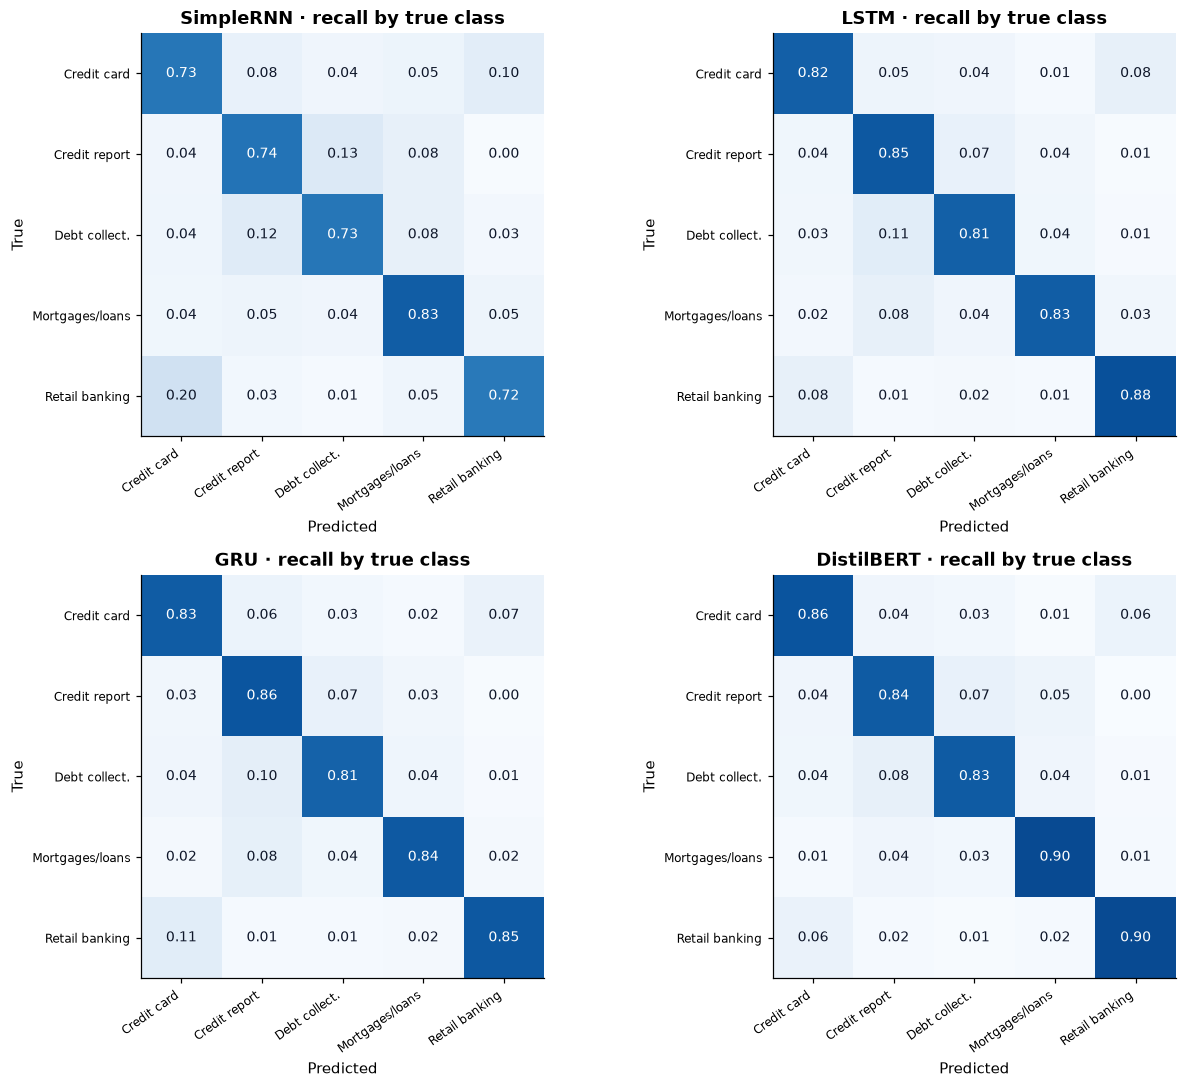

,credit_card,credit_reporting,debt_collection,mortgages_and_loans,retail_banking
True / predicted,,,,,
credit_card,1290,63,43,10,90
credit_reporting,224,4668,405,272,20
debt_collection,75,168,1746,87,21
mortgages_and_loans,28,78,58,1680,26
retail_banking,86,21,10,21,1208


In [16]:
fig, axes = plt.subplots(2,2,figsize=(12,10))
short_labels = ['Credit card','Credit report','Debt collect.','Mortgages/loans','Retail banking']
confusion_counts = {}
for ax, (kind, record) in zip(axes.flat, E['models'].items()):
    cm = pd.DataFrame(record['confusion']).iloc[:,1:].astype(int).to_numpy()
    confusion_counts[kind] = cm
    norm = cm / cm.sum(axis=1,keepdims=True)
    ax.imshow(norm, cmap='Blues',vmin=0,vmax=1)
    ax.set_xticks(range(5),short_labels,rotation=35,ha='right',fontsize=8)
    ax.set_yticks(range(5),short_labels,fontsize=8)
    ax.set_xlabel('Predicted');ax.set_ylabel('True');ax.set_title(NAMES[kind] + ' · recall by true class')
    for i in range(5):
        for j in range(5):
            ax.text(j,i,f'{norm[i,j]:.2f}',ha='center',va='center',fontsize=9,
                    color='white' if norm[i,j]>.5 else '#0f172a')
    assert cm.sum() == 12398
show()
display(pd.DataFrame(confusion_counts['distilbert'],index=LABELS,columns=LABELS).rename_axis('True / predicted'))

,precision,recall,f1-score,support
credit_card,0.7575,0.8623,0.8065,1496.0
credit_reporting,0.9340,0.8352,0.8818,5589.0
debt_collection,0.7719,0.8326,0.8011,2097.0
mortgages_and_loans,0.8116,0.8984,0.8528,1870.0
retail_banking,0.8850,0.8975,0.8912,1346.0


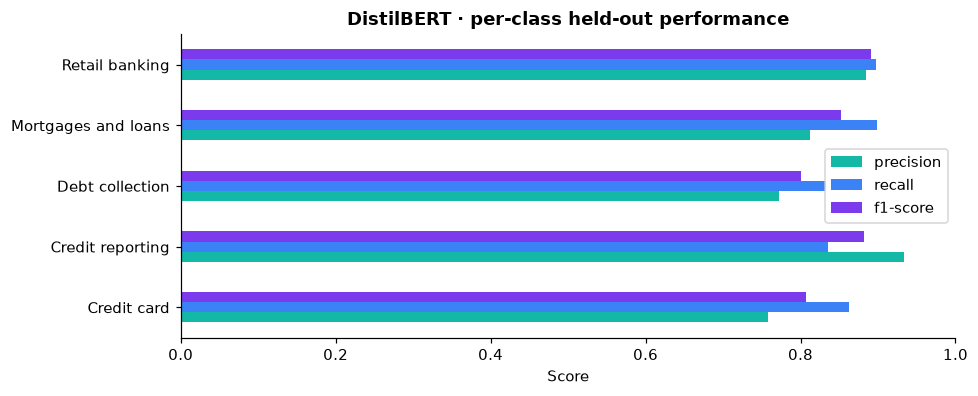

In [17]:
per_class = pd.DataFrame(E['models']['distilbert']['test']['per_class']).T.loc[LABELS]
display(per_class.round(4))
fig, ax = plt.subplots(figsize=(9,3.7))
per_class[['precision','recall','f1-score']].rename(index=PRETTY).plot.barh(ax=ax,
    color=['#14b8a6','#3b82f6','#7c3aed'])
ax.set_xlim(0,1); ax.set_xlabel('Score'); ax.set_title('DistilBERT · per-class held-out performance')
show()

DistilBERT leads this single run with **0.8467 macro F1**, compared with **0.8263 GRU**,
**0.8231 LSTM**, and **0.7263 SimpleRNN**. Its improvement over GRU is about **2.04 percentage
points of macro F1**. This is an observed comparison, not a claim of statistical superiority.
Credit-card and debt-collection F1 remain weaker than the best-performing classes, leaving room
for improved routing. The confusion matrices explain where aggregate scores hide mistakes.

## 11. Inspect mistakes and limitations
Error examples below are from the held-out reporting phase and are used only for explanation.
They were not fed back into training or model selection. High confidence does not ensure correctness.

In [18]:
error_rows = pd.DataFrame(E['models']['distilbert']['errors'])
incorrect = error_rows.loc[error_rows.correct.astype(str).str.lower().eq('false')].copy()
display(incorrect[['product','predicted_label','confidence','narrative']].head(5).assign(
    narrative=lambda x:x.narrative.str.slice(0,360)))
cm = confusion_counts['distilbert'].copy(); np.fill_diagonal(cm,0)
true_idx,pred_idx = np.unravel_index(cm.argmax(),cm.shape)
print(f'Largest off-diagonal count: {PRETTY[LABELS[true_idx]]} → '
      f'{PRETTY[LABELS[pred_idx]]}: {cm[true_idx,pred_idx]:,} complaints.')

Largest off-diagonal count: Credit reporting → Debt collection: 405 complaints.


,product,predicted_label,confidence,narrative
0,credit_reporting,mortgages_and_loans,0.99554366,year property tax due realized one mortgage es...
1,credit_card,retail_banking,0.99520725,free msg frm chase bank secure message frm cha...
2,credit_reporting,mortgages_and_loans,0.9950598,bought home back dealt mortgage forward bank t...
3,credit_card,retail_banking,0.9948257,im using cash app run square inc account locke...
4,credit_reporting,retail_banking,0.99470997,done written matter bank america told would in...


Main limitations are upstream preprocessing of unknown scope, possible semantic near-duplicates,
loss of later information in long complaints, one random seed, and an English five-category task.
Natural user text differs from the already-processed training source. A forced-choice classifier
also assigns unrelated text to a category. Its probabilities are **uncalibrated**, particularly with
class weighting; they should not be presented as guaranteed probabilities of correctness.

## 12. Classify new complaints and use the Gradio application
These newly written examples exercise the exported model without changing it. Their saved predictions
are produced by an actual clean-process CPU reload, separate from the historical test results.
They are demonstrations, not an additional generalization benchmark.

In [19]:
verification = E['app_verification']
demonstrations = verification.get('natural_examples',[])
if demonstrations:
    display(pd.DataFrame(demonstrations)[['input','expected_category','predicted_category','probability']])
else:
    print('Application verification evidence is pending; no predictions are fabricated.')
display(pd.DataFrame([E['benchmark']]))
print('Historical CPU timing is hardware-specific; it does not predict hosted latency.')
print('Current app verification:', verification.get('status'))
deployment = E['deployment']
if deployment.get('url'):
    display(Markdown(f"**Try the Gradio application:** [{deployment['url']}]({deployment['url']})"))
    print('Hosting verification:', deployment.get('status'))
else:
    print('No hosted URL has been verified yet.')

Historical CPU timing is hardware-specific; it does not predict hosted latency.
Current app verification: passed
No hosted URL has been verified yet.


,input,expected_category,predicted_category,probability
0,My credit report shows an account that I never...,credit_reporting,credit_reporting,0.851463
1,A debt collector keeps calling about a debt th...,debt_collection,debt_collection,0.981306
2,My mortgage servicer applied my payment incorr...,mortgages_and_loans,mortgages_and_loans,0.978274
3,My credit card was charged twice and the card ...,credit_card,credit_card,0.773713
4,My bank account was frozen and I cannot access...,retail_banking,retail_banking,0.899980


,device,batch_size,warmup_calls,measured_calls,median_ms,p95_ms,includes_preprocessing_and_tokenization,threads,recurrent_max_length,transformer_max_length,validation_reload_max_probability_difference
0,cpu,1,3,30,81.068943,139.305329,True,2,256,256,4.172325e-07


In [20]:
# Optional: use an existing local trained bundle. No download fallback is permitted.
ENABLE_LIVE_INFERENCE = False
if ENABLE_LIVE_INFERENCE:
    import os
    os.environ['USE_TF'] = '0'; os.environ['USE_FLAX'] = '0'; os.environ['HF_HUB_OFFLINE'] = '1'
    candidates = [Path.cwd(),Path.cwd().parent]
    project = next((p for p in candidates if (p/'deployment_model/bundle.json').exists()),None)
    if project is None:
        raise FileNotFoundError('Place this notebook in the project notebooks/ directory with the existing model bundle.')
    sys.path.insert(0,str(project/'src'))
    from complaints.inference import ComplaintPredictor
    predictor = ComplaintPredictor(project/'deployment_model',device='cpu')
    display(predictor.predict('A collector calls me every day about a debt that is not mine.'))
else:
    print('Live inference disabled. All default report cells run without model weights.')

Live inference disabled. All default report cells run without model weights.


## 13. Conclusions and reproducibility
The experiment delivers the four required trained architectures, shared audited splits, explicit
preprocessing and padding, learned custom embeddings, a genuinely fine-tuned transformer, required
metrics, and a Gradio application. DistilBERT is the validation-selected deployment model; GRU offers
a smaller recurrent alternative with lower measured test macro F1 in this run.

Useful future experiments include multiple seeds, validation-based calibration, long-document
strategies, and evaluation on naturally written complaints. These would be **new experiments**;
they should not overwrite the frozen held-out assessment.

**Full training reproduction:** use `consumer_complaint_training.ipynb` in Kaggle
with Internet and GPU T4 ×2. It embeds the full source, retrieves the pinned source version,
verifies fingerprints, prepares splits and encodings, trains the four models, freezes validation
selection, evaluates test once per compatible experiment and exports the bundle. Saved outputs document the historical Kaggle run; maintained source changes have not undergone another full GPU training run.

**Evidence map:** `reports/preparation_reports/` → quality and splits;
`reports/models/*/` → training histories and validation;
`reports/selection.json` → frozen selection;
`reports/final_test/` → held-out evaluation;
`reports/application_verification.json` → app checks;
`reports/deployment.json` → actual hosting state.

Assignment source: *INSTANT AI & DATA ANALYSIS TRAINING.pdf*, pages 17–19.
The assignment requires Gradio; Hugging Face Spaces is the selected hosting provider.

In [21]:
display(pd.DataFrame([E['environment']['versions']]).T.rename(columns={0:'Recorded training version'}))
print('Recorded training GPUs:', [g['name'] for g in E['environment']['gpus']])
print('Source CSV SHA-256:', audit['source_csv_sha256'])
print('Preparation identity:', E['recovery']['completed_preparation_id'])
print('Experiment signature:', E['selection']['signature'])
assert all(v['result']['signature'] == E['selection']['signature'] for v in E['models'].values())
assert all(v['test']['records'] == 12398 for v in E['models'].values())
print('Evidence consistency checks passed. No training was run in this walkthrough.')

Recorded training GPUs: ['Tesla T4', 'Tesla T4']
Source CSV SHA-256: a120ac8450cb3839bf0085bbae68f7c0f3b5351302cafd0bc85ae27a251010b4
Preparation identity: 4e3ead3e2e205566cb08dfb02fb7138ccc924c580f462808e3db5bc665f19b04
Experiment signature: bd457ca03f08e8a79677243e610ca2393dc21aefe70fde9dc10db0f32b83c23a
Evidence consistency checks passed. No training was run in this walkthrough.


,Recorded training version
torch,2.11.0+cu130
transformers,4.57.1
tokenizers,0.22.2
numpy,2.3.5
pandas,2.2.3
scikit-learn,1.8.0
safetensors,0.8.0
